# EDA: структура, качество и разнообразие МЭГ/ЭЭГ-рядов

Исследование двух источников проекта: **локальный Excel** `58voln_trial001_12.xlsx` и **публичный MNE sample**. Цель — понять состав данных, получить характеристики **каждого** ряда, увидеть различия амплитуд, временной и спектральной формы и оценить, что это означает для поиска разладок из `task.pdf`.

**Что здесь называется рядом:** в Excel — один канал одной пробы; в MNE — одна пара «проба × канал». Кроме основных физических рядов, в полной статистике MNE сохранены технические стимульные каналы. Источники исследуются отдельно: у них разные участники, эксперимент, длительность, предобработка и полнота метаданных.

Вычисления и визуализации вынесены в `utils/meg_eda.py`. Загрузка сигналов использует `utils/data_loading.py`. Все таблицы и полный PDF-атлас создаются в `eda/`; ноутбук содержит выполненные результаты.

**Запуск:** установите `requirements.txt`, выберите соответствующее ядро и выполните **Restart & Run All**. MNE sample при первом обращении загружает архив около 1,65 ГБ; распакованные данные занимают около 2,7 ГБ. `RUN_MNE=False` позволяет исследовать только Excel. При подготовке этого ноутбука оба источника обработаны.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from IPython.display import display, Markdown

PROJECT_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "src").is_dir() and (parent / "utils" / "paths.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from utils.paths import DATA_DIR, EXPERIMENTS_DIR
from utils import data_loading as data
from utils import meg_eda as eda

%matplotlib inline
plt.rcParams.update({"figure.dpi": 95, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 20)
SEED = 42
RUN_MNE = True
SAVE_ALL_CHANNELS_PDF = True
DATA_FILE = DATA_DIR / "excel-data" / "58voln_trial001_12.xlsx"
EXCEL_OUTPUT = EXPERIMENTS_DIR / "eda" / "excel"
MNE_OUTPUT = EXPERIMENTS_DIR / "eda" / "mne"
EXCEL_OUTPUT.mkdir(parents=True, exist_ok=True)


## 1. Три разных смысла «типов данных»

| Уровень | Что различаем | Как трактовать |
|---|---|---|
| Источник и формат | Excel: одна проба; FIF/MNE: непрерывная запись, события, эпохи | У источников разный контекст и степень документированности |
| Измерительный канал | `grad`, `mag`, `eeg`, `eog`, `stim` | Это разные измеряемые величины и единицы |
| Условие эксперимента | `auditory/left`, `auditory/right`, `visual/left`, `visual/right` в MNE sample | Тип и сторона предъявленного стимула |
| Наблюдаемая форма | Гладкость, разброс, спектр, локальные изменения, общая динамика | Это признаки конкретной записи, а не заранее известные классы физиологических процессов |

`grad` измеряет пространственное изменение магнитного поля; в системе Neuromag две планарные ориентации на одной сенсорной позиции обозначаются окончаниями **2** и **3**. `mag` измеряет магнитное поле (окончание **1**). `eeg` — электрический потенциал относительно референса; `eog` регистрирует глазную активность и полезен при поиске артефактов; `stim` содержит дискретные коды событий. Единицы MNE: `grad` — T/m, `mag` — T, `eeg/eog` — V. Поэтому абсолютные std разных типов сравниваются **раздельно**. [Типы и единицы MNE](https://mne.tools/1.2/overview/implementation.html), [соглашение об именах Neuromag](https://mne.tools/1.4/auto_tutorials/preprocessing/15_handling_bad_channels.html).

Для Excel тип датчика определяется **предположительно по имени**: в файле нет заголовка с физическими единицами, геометрии датчиков, истории фильтрации и словаря событий. Все амплитуды этого источника оставлены в исходных единицах экспорта.

## 2. Аудит Excel и краткие результаты

Загружаем **все каналы**, без случайной выборки, удаления выбросов, сглаживания или интерполяции. Отдельный аудит считывает временную строку и технические маркеры, которые основной загрузчик корректно пропускает. Дополнительно сразу рассчитываются общая структура зависимостей, исследовательские группы и пилотная PELT-сегментация всех каналов.

In [2]:
excel_series = data.load_xlsx_series(str(DATA_FILE))
excel_data, excel_times, excel_metadata = eda.series_arrays(excel_series, DATA_FILE.stem)
excel_audit = eda.audit_excel(DATA_FILE)
excel = eda.analyze_series(excel_data, excel_times, excel_metadata)
dependence = eda.dependence_analysis(excel)
groups = eda.exploratory_groups(excel["statistics"], n_groups=3)
pilot = eda.pilot_segmentation(excel, penalty=0.02, min_duration_seconds=0.03)
examples = eda.representative_indices(excel["statistics"])

print("Массив сигналов:", excel_data.shape, "dtype:", excel_data.dtype)
display(pd.DataFrame([excel_audit["summary"]]).drop(columns="sha256").T.rename(columns={0: "Значение"}))
display(excel_audit["rows"].groupby("row_type").agg(rows=("row_name", "size"), nonfinite=("n_nonfinite", "sum")))
display(excel_metadata.groupby(["channel_type", "type_evidence", "orientation"]).size().rename("Каналов").reset_index())
display(excel_audit["markers"])


Массив сигналов: (204, 2001) dtype: float64


,Значение
file,58voln_trial001_12.xlsx
sheet,Лист1
samples,2001
sfreq_hz,1000.0
t_start_s,0.0
t_end_s,2.0
max_dt_error_s,0.0


,rows,nonfinite
row_type,,
signal,204,0
stimulus,1,0
time,1,0


,channel_type,type_evidence,orientation,Каналов
0,grad,name only (unverified),2,102
1,grad,name only (unverified),3,102


,marker_channel,sample,time_s,code,duration_s
0,STI101,495,0.495,1.0,0.003
1,STI101,662,0.662,32.0,0.003


In [3]:
display(Markdown(eda.excel_findings(excel, excel_audit, dependence, groups, pilot)))


**Факты по этому файлу.** Исследованы все **204** рядов, по **2001** отсчётов; частота 1000.0 Гц. Пропущенных/бесконечных значений **0**, постоянных рядов **0**. Найдено **102** пар ориентаций 2/3; других типов датчиков в экспорте по именам не обнаружено.

**Амплитуды и форма.** std меняется от 2.11e-12 до 1.72e-11 исх. ед. (разница в 8.14 раза). Максимум у **MEG2043**. По правилу 6×1.4826×MAD экстремальных отсчётов не найдено ни в одном канале; это не исключает артефакты других типов. Медианная корреляция соседних отсчётов 0.881: временные отсчёты явно не независимы.

**Спектр и общая структура.** Наибольшая медианная относительная мощность приходится на **alpha_8_13** (37.2% мощности 1–45 Гц). Частотный шаг 1.953 Гц; низкочастотные полосы оцениваются грубо. Первая PCA-компонента объясняет **18.8%** дисперсии стандартизованных каналов, 90% — **25** компонент. Медиана корреляции двух ориентаций одной позиции -0.044; ориентации не взаимозаменяемы.

**Применимость к разладкам.** При β=0.02 и минимуме 30 отсчётов PELT даёт от 2 до 11 границ на канал, медиана **6**. Это характеристика выбранного критерия; без ручной разметки нельзя оценить точность обнаружения.

**Границы вывода.** Один участник/одна проба не дают популяционного вывода. Коды STI101 требуют словаря именно этого эксперимента. Единицы и история фильтрации экспорта не документированы. Названия каналов поддерживают гипотезу о планарных градиометрах, но не заменяют метаданные прибора. Три группы по форме — описательный результат при фиксированном k, а не три типа мозговой активности.

В `STI101` показаны реальные числовые коды и моменты их появления. Красные пунктирные линии на последующих графиках обозначают эти маркеры. Значения `1` и `32` требуют словаря **данного** эксперимента: совпадение чисел с MNE sample само по себе не подтверждает их смысл. Нуль времени Excel — начало экспортированного фрагмента.

Средние практически нулевые у всех каналов. Это согласуется с предварительным центрированием, но по одному файлу нельзя восстановить, как именно выполнялась предобработка. Точность временной сетки проверена численно; никакая привязка к физиологическим событиям не добавляется.

## 3. Характеристики каждого ряда

Для **всех 204 каналов** получаем описательные статистики, устойчивые меры разброса, характеристики формы распределения, зависимости соседних отсчётов, временных изменений и спектра. Ниже — полная прокручиваемая таблица, а не первые несколько строк. CSV создаётся в разделе экспорта.

- `std` использует **ddof=1**; `skewness` и `excess_kurtosis` — стандартизованные моменты без поправки на смещение. Для нормального распределения эксцесс равен 0.
- `mad = median(|y−median(y)|)`. Флаг экстремальности: `|y−median| > 6 × 1.4826 × MAD`. Это прозрачная эвристика; отсутствие таких отсчётов не гарантирует отсутствие артефактов.
- `acf_lag1` — корреляция соседних отсчётов; `roughness = std(diff(y))/std(y)`. Они описывают зависимость и быстрые колебания.
- `half_mean_shift_sd` — изменение среднего между половинами ряда в единицах std; `half_std_log2_ratio` — логарифм отношения их std: **+1 означает удвоение**, −1 — уменьшение вдвое. Это описательные индикаторы изменения поведения.
- Неопределённые величины у постоянных/неполных рядов остаются NaN; пропуски учитываются явно. Амплитудные столбцы сохраняют единицы источника.

Для сглаженных и автокоррелированных сигналов 2001 отсчёт не означает 2001 независимое наблюдение. Поэтому здесь нет наивных p-value теста нормальности или тестов различий, рассматривающих отсчёты как независимые пробы.

In [4]:
display(eda.scroll_table(excel["statistics"], max_height=500, scientific=True))
display(eda.scroll_table(pd.DataFrame(eda.FEATURE_DESCRIPTIONS.items(), columns=["Признак", "Определение"]), max_height=300))


source,channel_name,channel_type,type_evidence,unit,site,orientation,marked_bad,epoch_idx,condition,series_id,n_samples,n_finite,missing_fraction,mean,median,std,rms,min,max,ptp,iqr,mad,skewness,excess_kurtosis,robust_outlier_fraction,constant,q01,q05,q25,q75,q95,q99,acf_lag1,roughness,zero_crossing_fraction,flat_step_fraction,linear_slope_per_s,half_mean_shift_sd,half_std_log2_ratio,psd_peak_hz,spectral_centroid_hz,spectral_entropy,delta_1_4_fraction,theta_4_8_fraction,alpha_8_13_fraction,beta_13_30_fraction,gamma_30_45_fraction,line50_fraction,high80_fraction
58voln_trial001_12,MEG0113,grad,name only (unverified),export units (unverified),011,3,False,0,not documented,58voln_trial001_12/ep0/MEG0113,2001,2001,0.00000e+00,7.16295e-28,1.61956e-14,4.46873e-12,4.46761e-12,-1.44086e-11,1.25677e-11,2.69762e-11,6.31318e-12,3.14302e-12,-1.03021e-01,-1.99927e-01,0.00000e+00,False,-1.12296e-11,-7.09369e-12,-3.07421e-12,3.23897e-12,7.29412e-12,9.59097e-12,8.05282e-01,6.24193e-01,1.97000e-01,0.00000e+00,2.44644e-12,6.07954e-01,1.31231e-01,9.76562e+00,2.16619e+01,7.80937e-01,1.58007e-01,1.18362e-01,4.15155e-01,2.33719e-01,7.47567e-02,1.73700e-02,3.92073e-02
58voln_trial001_12,MEG0112,grad,name only (unverified),export units (unverified),011,2,False,0,not documented,58voln_trial001_12/ep0/MEG0112,2001,2001,0.00000e+00,1.94166e-27,-5.80473e-14,4.34101e-12,4.33992e-12,-1.54029e-11,1.45110e-11,2.99139e-11,5.73840e-12,2.85480e-12,3.34750e-02,1.97736e-01,0.00000e+00,False,-1.05778e-11,-6.89249e-12,-2.84971e-12,2.88869e-12,7.20645e-12,1.07479e-11,7.19343e-01,7.49116e-01,2.48000e-01,0.00000e+00,2.59989e-13,1.45877e-01,7.48038e-02,9.76562e+00,2.67887e+01,8.14347e-01,1.40834e-01,1.65987e-01,4.18057e-01,1.64652e-01,1.10470e-01,1.63121e-02,8.80330e-02
58voln_trial001_12,MEG0122,grad,name only (unverified),export units (unverified),012,2,False,0,not documented,58voln_trial001_12/ep0/MEG0122,2001,2001,0.00000e+00,-6.60147e-29,-5.23193e-14,3.53856e-12,3.53767e-12,-1.16642e-11,1.23939e-11,2.40581e-11,4.82391e-12,2.41189e-12,1.05057e-01,-8.40375e-02,0.00000e+00,False,-7.73507e-12,-5.62387e-12,-2.45169e-12,2.37223e-12,5.78764e-12,8.38220e-12,7.51132e-01,7.05351e-01,2.39000e-01,0.00000e+00,-1.02286e-13,4.01073e-02,6.98025e-02,1.17187e+01,2.46323e+01,8.34429e-01,2.64845e-01,9.51143e-02,2.55877e-01,2.76270e-01,1.07894e-01,2.65176e-02,7.13048e-02
58voln_trial001_12,MEG0123,grad,name only (unverified),export units (unverified),012,3,False,0,not documented,58voln_trial001_12/ep0/MEG0123,2001,2001,0.00000e+00,-2.88830e-27,1.39947e-13,5.55962e-12,5.55824e-12,-2.07234e-11,1.82775e-11,3.90009e-11,7.31328e-12,3.66162e-12,1.16229e-02,5.43685e-02,0.00000e+00,False,-1.28821e-11,-9.14173e-12,-3.72415e-12,3.58912e-12,9.25051e-12,1.28776e-11,7.91816e-01,6.45249e-01,2.06000e-01,0.00000e+00,6.58136e-13,6.00301e-03,1.76075e-01,9.76562e+00,2.48674e+01,7.99509e-01,1.24142e-01,1.88953e-01,4.29019e-01,1.62890e-01,9.49965e-02,2.66782e-02,6.60254e-02
58voln_trial001_12,MEG0132,grad,name only (unverified),export units (unverified),013,2,False,0,not documented,58voln_trial001_12/ep0/MEG0132,2001,2001,0.00000e+00,-4.02438e-28,-9.78355e-14,4.70929e-12,4.70811e-12,-1.54168e-11,1.61904e-11,3.16072e-11,6.19298e-12,3.09695e-12,1.43161e-01,-5.37152e-02,0.00000e+00,False,-1.04274e-11,-7.57552e-12,-3.14504e-12,3.04795e-12,7.97604e-12,1.13630e-11,7.82340e-01,6.59627e-01,1.99500e-01,0.00000e+00,-7.78225e-13,-2.65586e-02,-6.56146e-02,1.17187e+01,2.17705e+01,7.99903e-01,2.91427e-01,9.92158e-02,2.59661e-01,2.66554e-01,8.31423e-02,3.48708e-02,6.60829e-02
58voln_trial001_12,MEG0133,grad,name only (unverified),export units (unverified),013,3,False,0,not documented,58voln_trial001_12/ep0/MEG0133,2001,2001,0.00000e+00,-9.75388e-28,-2.57832e-14,6.00210e-12,6.00060e-12,-1.83123e-11,1.76733e-11,3.59856e-11,7.63156e-12,3.82040e-12,5.46867e-02,9.65557e-03,0.00000e+00,False,-1.34414e-11,-1.02229e-11,-3.84618e-12,3.78538e-12,1.01054e-11,1.46203e-11,8.29203e-01,5.84334e-01,1.95000e-01,0.00000e+00,2.08006e-12,3.

Признак,Определение
n_samples,"Число отсчётов, включая нечисловые значения"
n_finite,Число конечных значений; Inf не включаются
missing_fraction,Доля NaN и Inf; они не интерполируются
mean,"Среднее, исходные единицы"
median,"Медиана, исходные единицы"
std,Выборочное стандартное отклонение (ddof=1)
rms,Среднеквадратичная амплитуда относительно нуля
min,Минимум
max,Максимум
ptp,Размах max−min


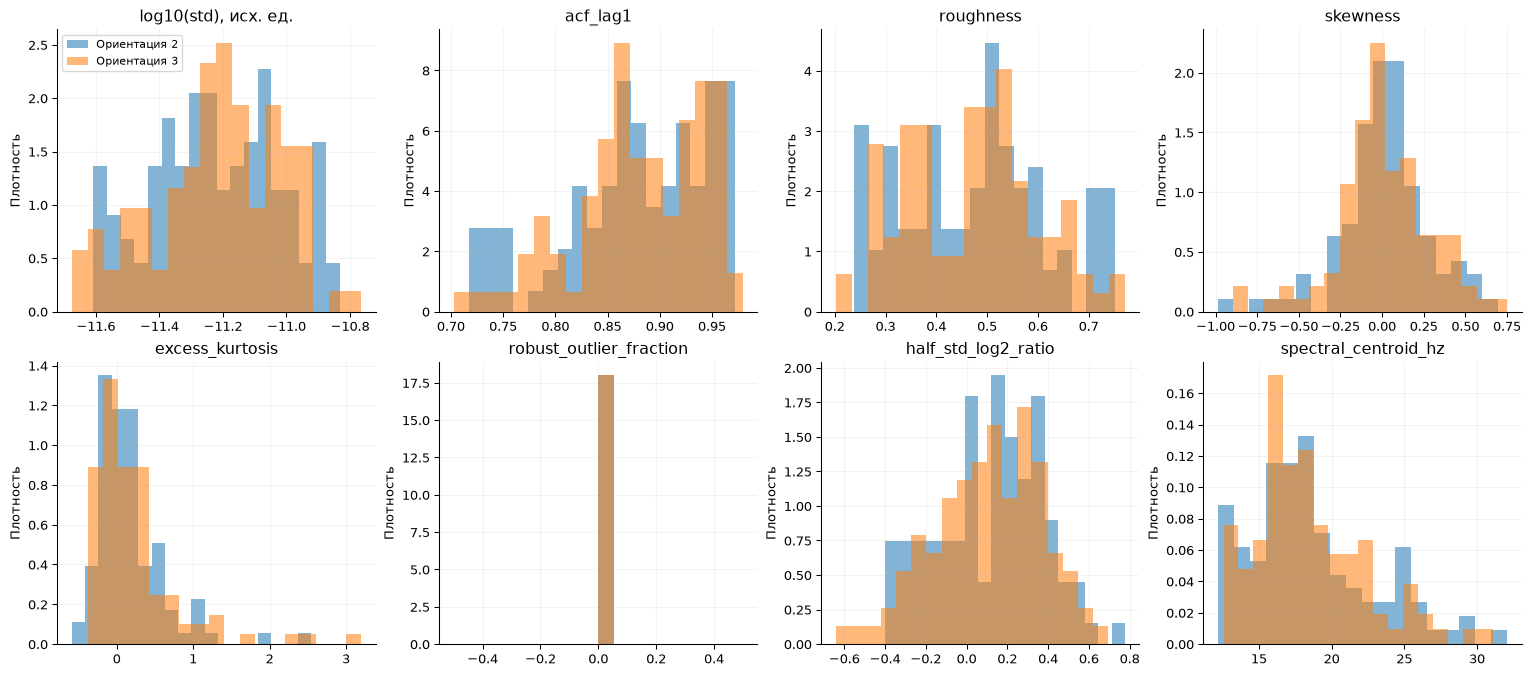

In [5]:
eda.plot_feature_distributions(excel["statistics"])
plt.show()


Гистограммы показывают вариабельность **между каналами**. Ориентации 2 и 3 показаны отдельно. Сдвиг или перекрытие гистограмм не являются доказательством двух классов нейронной активности: датчики расположены в разных местах и сами ряды пространственно зависимы.

## 4. Визуализация всех рядов и характерных примеров

На каждой карте присутствуют **все строки Excel**. Первая сохраняет амплитудные различия; вторая отдельно центрирует и нормирует каждую строку для сравнения формы. Для цвета используется симметричный 99,5%-квантиль абсолютных амплитуд: отдельные значения могут насыщать шкалу, но данные не обрезаются. Отрицательный цвет соответствует отрицательной амплитуде, а не подавлению активности.

Отдельные примеры выбираются воспроизводимо: минимальный, медианный и максимальный std, наибольшая шероховатость, доля экстремальных значений и изменение std между половинами. При совпадении критериев берутся дополнительные каналы; этим примерам не приписывается нейрофизиологическая репрезентативность.

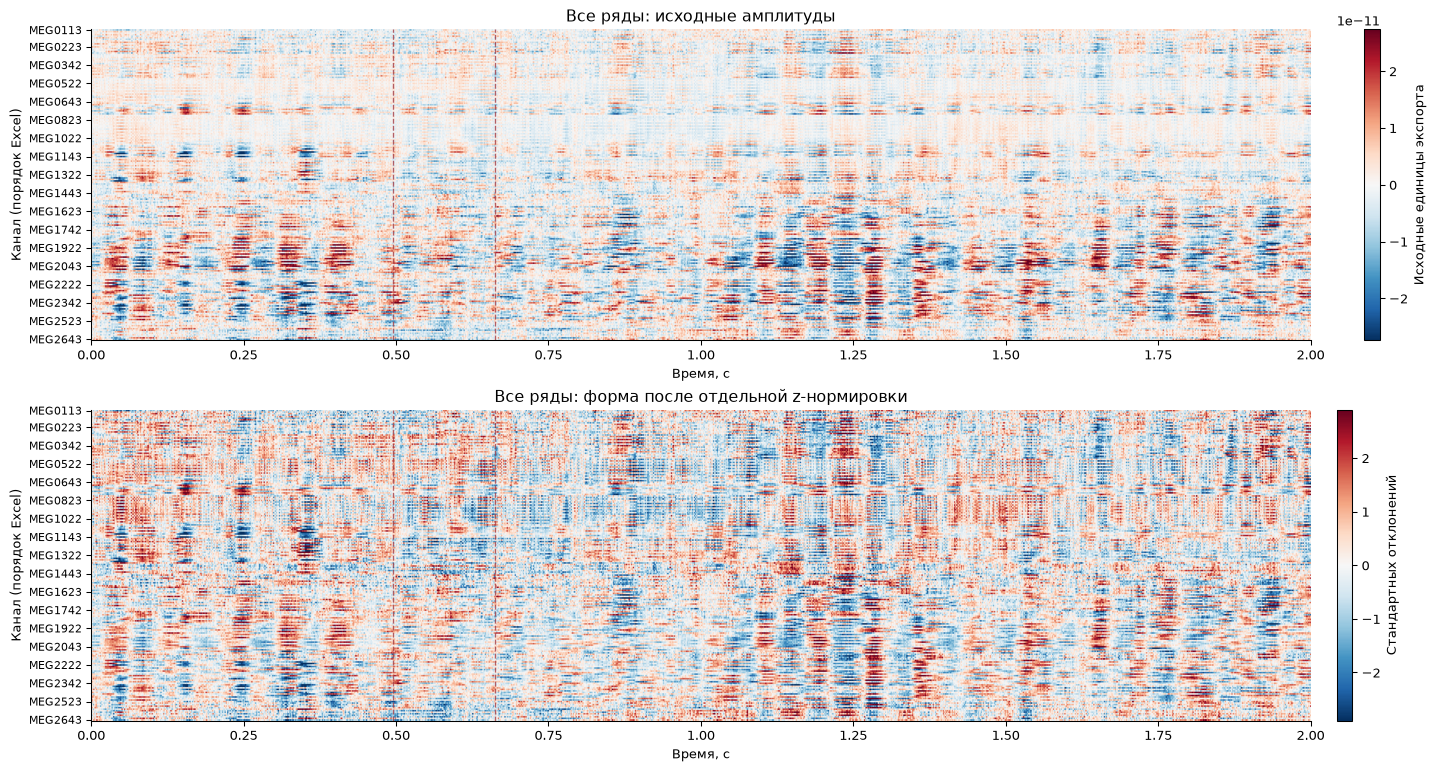

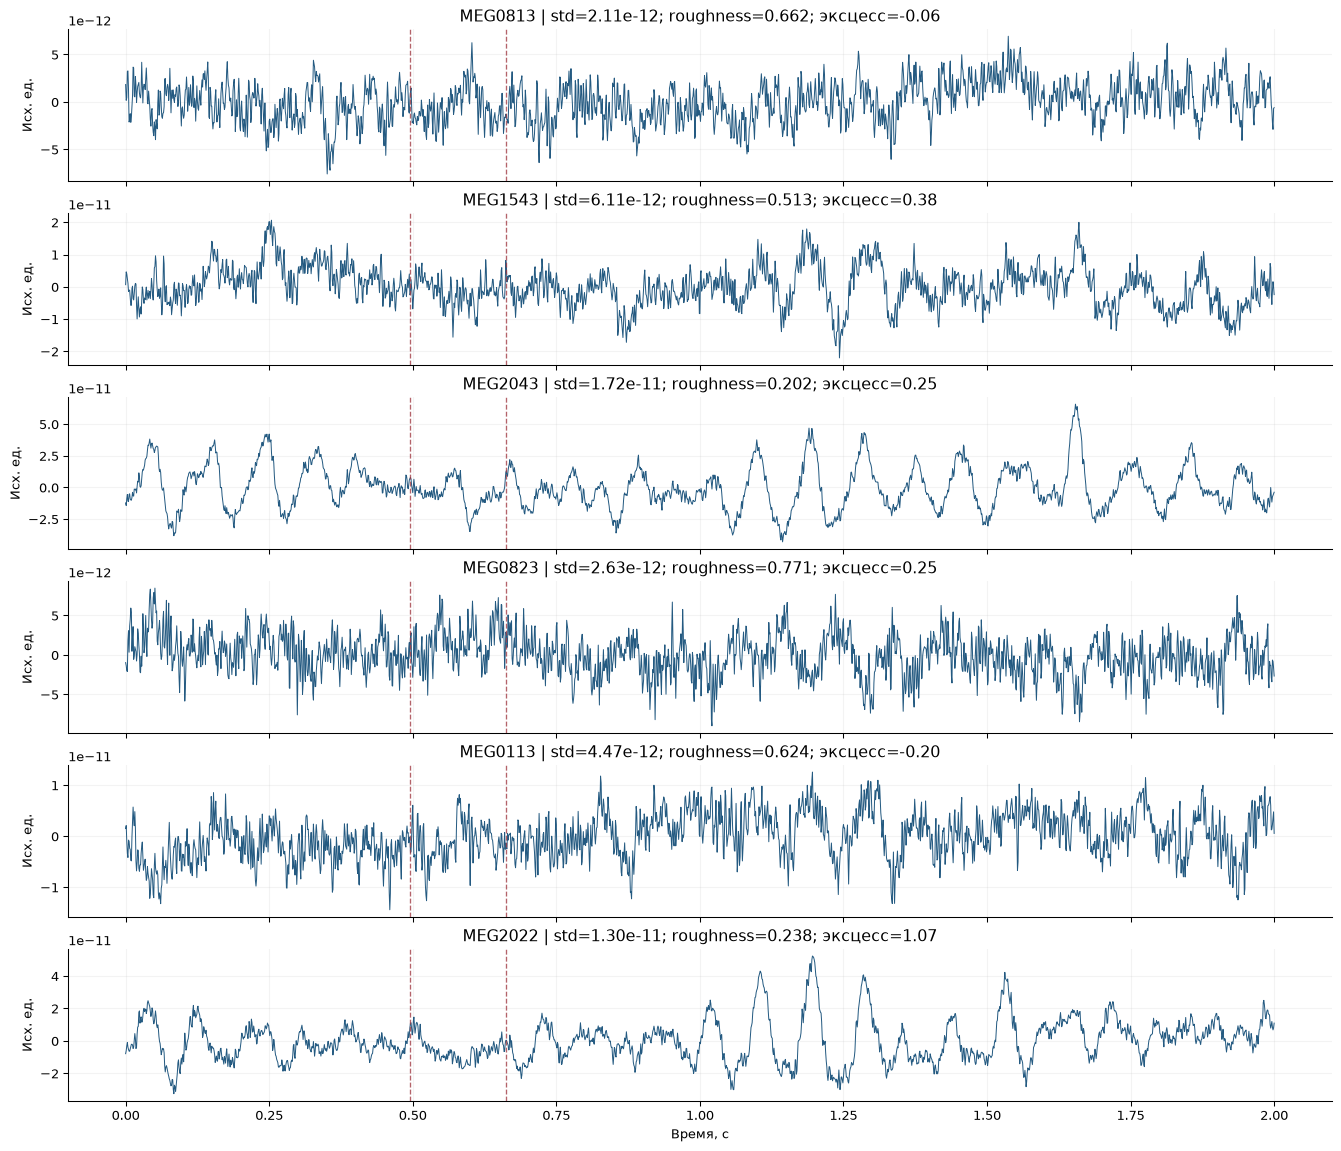

In [6]:
eda.plot_all_series(excel, excel_audit["markers"])
plt.show()
eda.plot_representatives(excel, examples, excel_audit["markers"])
plt.show()


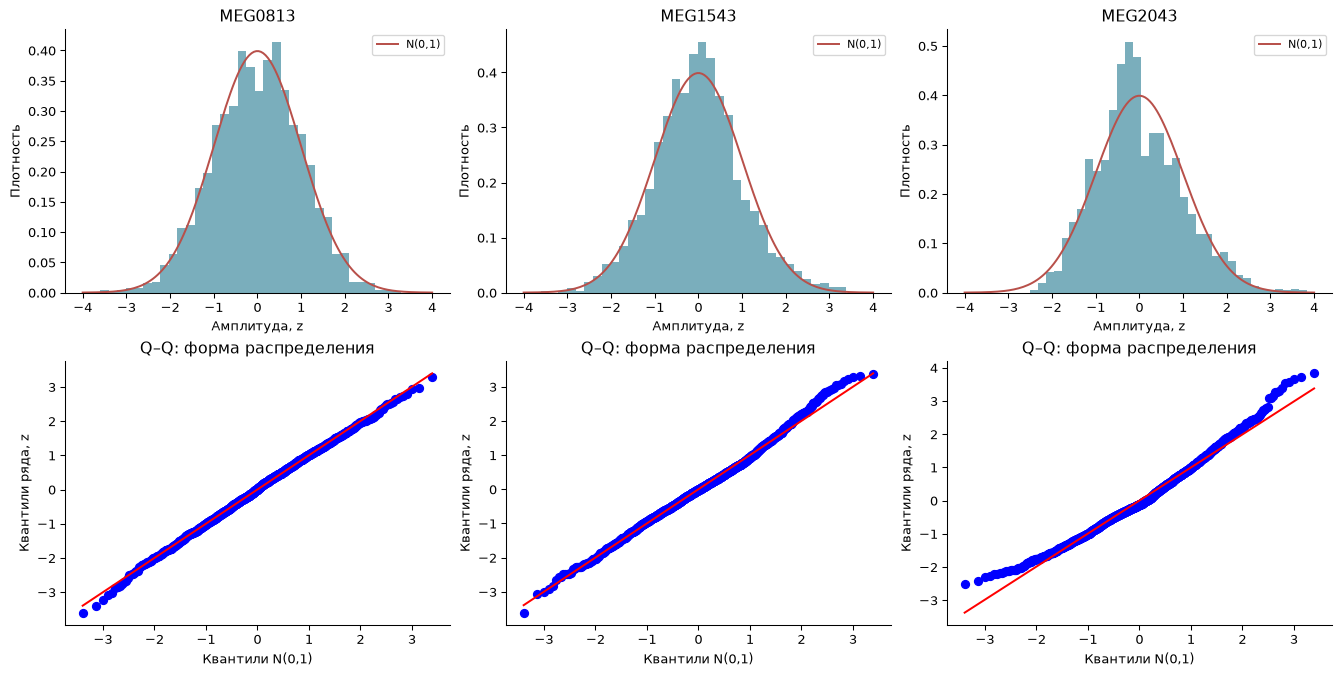

In [7]:
eda.plot_marginal_shapes(excel, examples[:3])
plt.show()


Q–Q-графики сравнивают форму эмпирического распределения с нормальным. Отклонения на концах указывают на различие хвостов, изгиб — на отличие формы. Они не объясняют источник отличий: в одном временном ряду могут смешиваться разные локальные режимы. Графики являются описательными; независимость отсчётов не предполагается.

## 5. Спектральное исследование

Оценка Welch: окно Hann, **512 отсчётов**, перекрытие 50%, удаление среднего в каждом окне; частотный шаг для Excel около **1,953 Гц**. Нулевое дополнение не используется. Цветовая карта спектральной формы нормируется на суммарную мощность 1–100 Гц отдельно для каждого канала; абсолютная PSD сохраняет единицы экспорта²/Гц.

Полосы `[1,4)`, `[4,8)`, `[8,13)`, `[13,30)`, `[30,45)` — условные описательные интервалы. Их мощности рассчитаны суммированием равномерных PSD-бинов и нормированы на 1–45 Гц; по каждому непостоянному ряду сумма долей равна 1. Грубая сетка особенно ограничивает интерпретацию низких частот: узкий пик на границе полосы распределяется между соседними бинами.

Около 50 Гц дополнительно измеряется доля мощности `[48,52)` относительно 1–100 Гц. Повышение этой доли служит поводом проверить сетевую помеху, но одного числа недостаточно для её установления. История фильтрации Excel неизвестна.

Welch: nperseg=512, Δf=1.9531 Гц


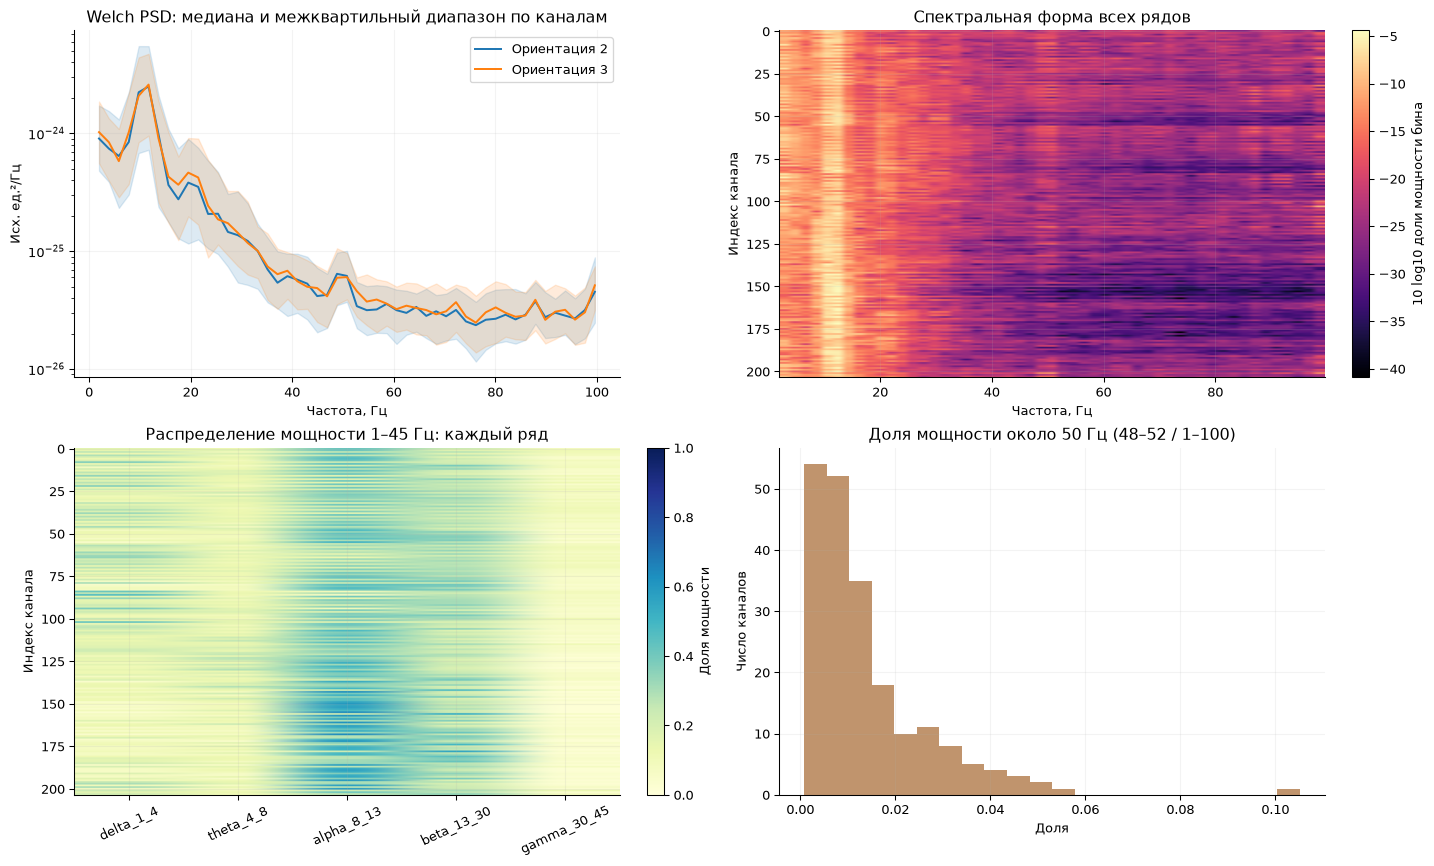

,channel_name,psd_peak_hz,spectral_centroid_hz,spectral_entropy,line50_fraction,high80_fraction
201,MEG2632,1.953125,32.071548,0.870299,0.105187,0.120979
7,MEG0142,11.718750,26.385871,0.813000,0.053947,0.075251
115,MEG1542,11.718750,29.560926,0.875347,0.052200,0.086067
203,MEG2643,11.718750,20.524896,0.789447,0.050723,0.034459
10,MEG0222,1.953125,25.721557,0.855467,0.047494,0.063765
18,MEG0322,1.953125,25.364761,0.859745,0.044197,0.064424
34,MEG0523,11.718750,27.267986,0.862192,0.043532,0.085254
38,MEG0542,1.953125,25.072467,0.845950,0.041356,0.069591
32,MEG0513,1.953125,29.467896,0.872829,0.040889,0.102147
56,MEG0813,11.718750,25.461936,0.846174,0.040792,0.073679


In [8]:
print(f"Welch: nperseg={excel['nperseg']}, Δf={excel['frequency_resolution_hz']:.4f} Гц")
eda.plot_spectra(excel)
plt.show()

spectral_columns = ["channel_name", "psd_peak_hz", "spectral_centroid_hz", "spectral_entropy", "line50_fraction", "high80_fraction"]
display(excel["statistics"][spectral_columns].sort_values("line50_fraction", ascending=False).head(10))


## 6. Локальные изменения во времени

Сравнение половин ряда может пропустить краткий переход. Поэтому анализируем локальное среднее и std в скользящем окне около **101 мс**. После отдельной z-нормировки каналов показатели становятся сопоставимыми по масштабу. На картах показаны все каналы, а по времени вычисления отображаются с шагом 10 отсчётов. У краёв оставлены только полные окна.

Совместные изменения многих каналов заслуживают внимания при выборе участков для разладок. Возможные причины включают общий сигнал, движение, помеху и предобработку; сами карты не различают эти объяснения. Близость к маркеру — наблюдение, требующее дальнейшей проверки.

Окно: 101 отсчётов, 101.0 мс


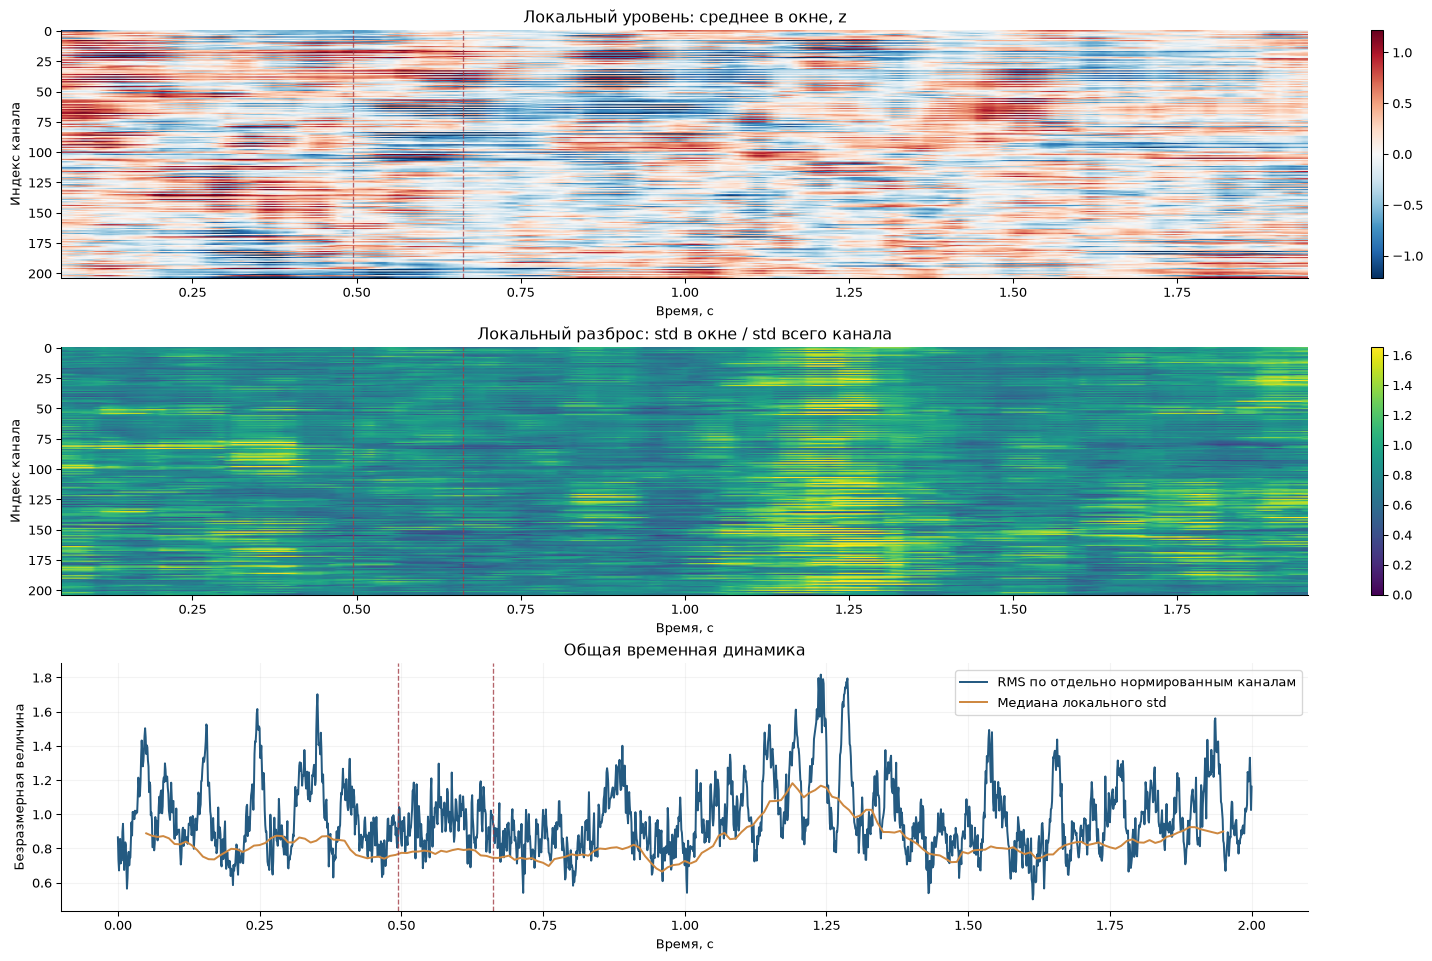

In [9]:
temporal = eda.temporal_profiles(excel, window_seconds=0.101)
print(f"Окно: {temporal['window_samples']} отсчётов, {temporal['window_seconds']*1000:.1f} мс")
eda.plot_temporal_profiles(excel, temporal, excel_audit["markers"])
plt.show()


## 7. Связи между каналами, пары датчиков и PCA

Корреляционная матрица описывает совместную временную форму всех 204 каналов. Положительная и отрицательная корреляция одинаково могут отражать общую компоненту с разным знаком. Для каждой сенсорной позиции дополнительно сравниваем ориентации 2/3; положительная корреляция между ними не обязательна.

PCA рассчитана по **отдельно стандартизованным каналам**: различия усиления не определяют результат. Доля объяснённой дисперсии показывает, насколько многоканальная запись допускает компактное линейное представление. Число компонент не оценивает число нейронных источников. Корреляция при нулевом сдвиге не означает причинную связь или функциональную связность.

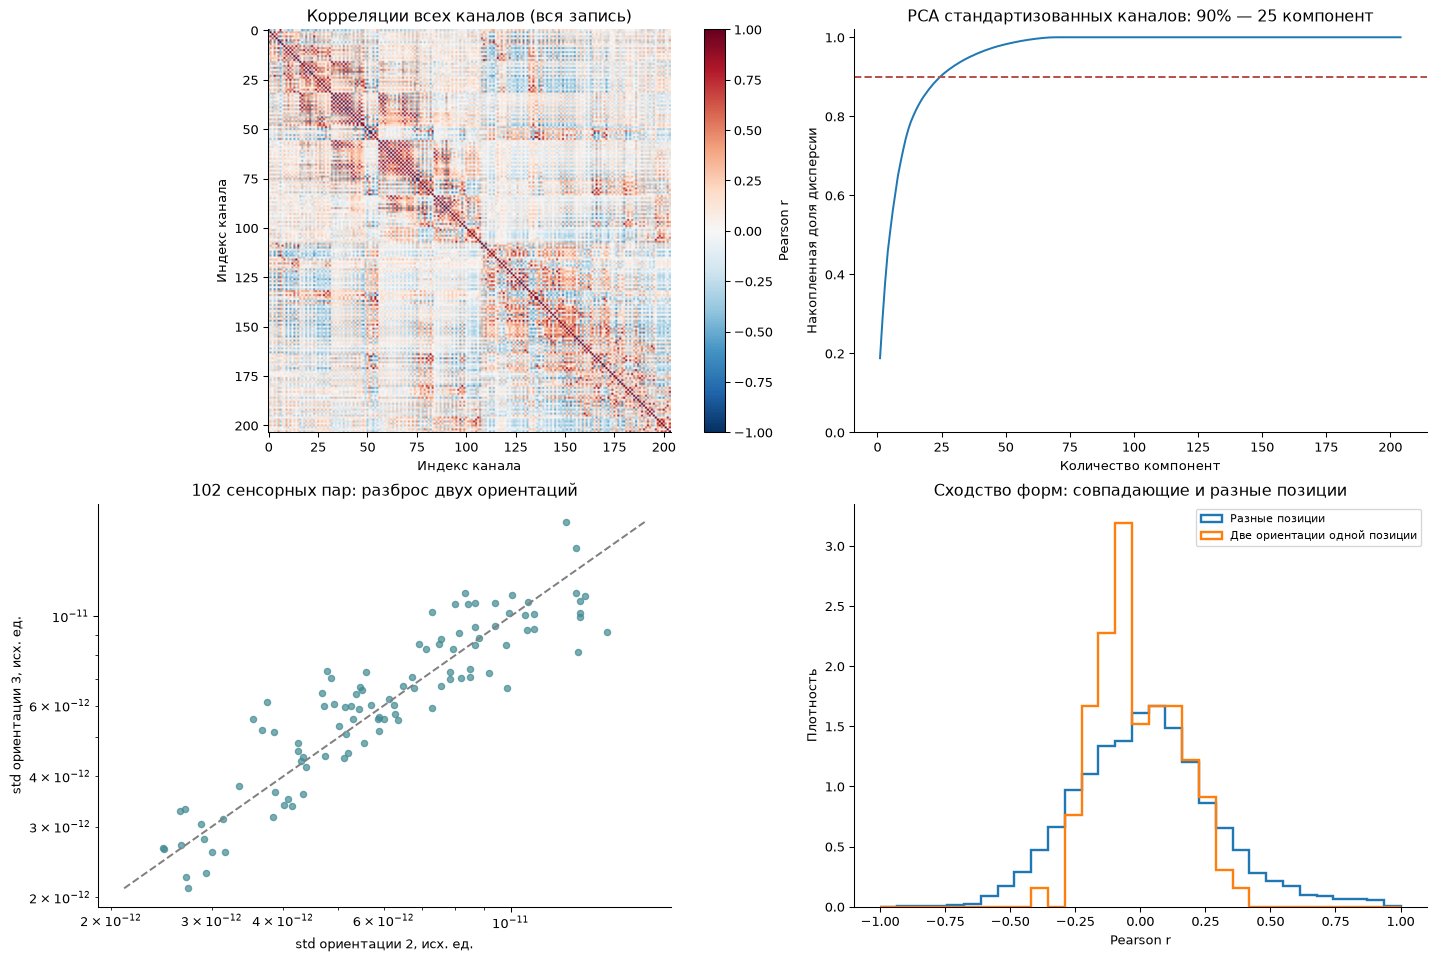

Эффективный ранг 1/sum(p_i²): 13.44


,correlation,std_2,std_3
count,102.000000,1.020000e+02,1.020000e+02
mean,-0.003900,6.679575e-12,6.722276e-12
std,0.156794,3.067159e-12,2.903620e-12
min,-0.372245,2.463114e-12,2.107753e-12
25%,-0.117387,4.311488e-12,4.579329e-12
50%,-0.043769,5.885594e-12,6.323454e-12
75%,0.121377,8.485627e-12,8.722463e-12
max,0.416181,1.472359e-11,1.716645e-11


,channel_a,channel_b,same_site,correlation,abs_r
9761,MEG0742,MEG1833,False,0.956221,0.956221
10130,MEG0822,MEG1013,False,0.954982,0.954982
6681,MEG0532,MEG0613,False,0.951097,0.951097
11256,MEG0942,MEG1023,False,0.944401,0.944401
6511,MEG0522,MEG0533,False,0.936276,0.936276
13165,MEG1133,MEG2223,False,0.935548,0.935548
17948,MEG1733,MEG1942,False,0.934436,0.934436
6172,MEG0512,MEG0522,False,0.933050,0.933050
10554,MEG0912,MEG0922,False,0.928736,0.928736
14152,MEG1233,MEG1242,False,0.927917,0.927917


In [10]:
eda.plot_dependence(excel, dependence)
plt.show()
print(f"Эффективный ранг 1/sum(p_i²): {dependence['effective_rank']:.2f}")
display(dependence["pairs"].describe())
strong_pairs = dependence["all_pairs"].assign(abs_r=lambda t: t.correlation.abs()).sort_values("abs_r", ascending=False)
display(strong_pairs.head(12))


## 8. Исследовательские группы по форме

Дополнительно группируем каналы **без амплитудных признаков**: шероховатость, ACF(1), асимметрия, эксцесс, спектральный центр и энтропия. Признаки приводятся к масштабу `(x−median)/IQR`, крайние значения ограничиваются ±10 **только в признаковом пространстве**. Исходные сигналы не меняются. Иерархическая кластеризация Ward строит **три группы при заранее заданном k=3**.

Такая группировка помогает выбрать разнообразные примеры: более быстрые/широкополосные колебания, более гладкие ряды и отличающиеся формы распределений. Она не устанавливает, что в природе есть ровно три класса. Различия на этих же признаках ожидаемы по построению; устойчивость групп ещё не проверена на других пробах.

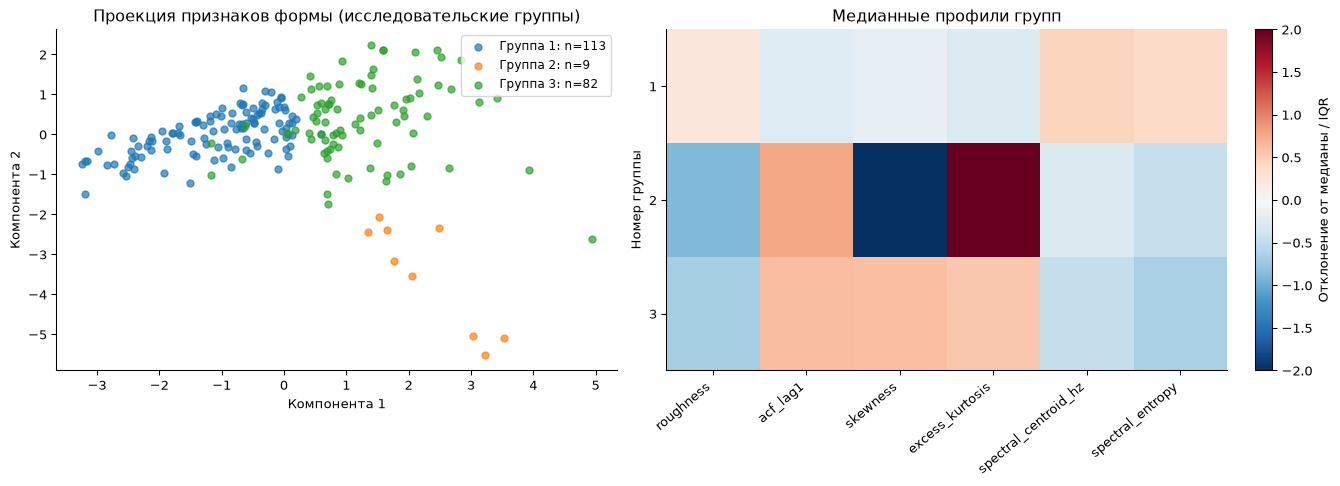

,n_channels,median_roughness,median_acf1,median_centroid_hz,median_entropy,median_excess_kurtosis
exploratory_group,,,,,,
1,113,0.532643,0.858147,19.837521,0.771327,-0.053715
2,9,0.310859,0.951687,16.415396,0.687281,1.372242
3,82,0.354221,0.937230,15.537825,0.668486,0.312650


**Качественное чтение текущего разбиения.** Группа **1** (113 каналов) имеет наибольший медианный спектральный центр (19.8 Гц) и roughness=0.53: в ней относительно больше быстрых колебаний. У группы **2** (9 каналов) наибольший медианный эксцесс (1.37), то есть сильнее отличие хвостов от нормальной формы. Группа **3** имеет более низкий спектральный центр (15.5 Гц) и ACF(1)=0.94. Границы этих групп зависят от признаков, их масштаба и выбранного k.

In [11]:
eda.plot_groups(groups)
plt.show()
group_table = excel["statistics"].assign(exploratory_group=groups["labels"])
display(group_table.groupby("exploratory_group").agg(
    n_channels=("channel_name", "size"), median_roughness=("roughness", "median"),
    median_acf1=("acf_lag1", "median"), median_centroid_hz=("spectral_centroid_hz", "median"),
    median_entropy=("spectral_entropy", "median"), median_excess_kurtosis=("excess_kurtosis", "median"),
))

display(Markdown(eda.group_findings(excel["statistics"], groups)))


## 9. Связь с задачей детекции разладок

Для каждого Excel-канала запущен ранее реализованный **точный PELT с прямоугольной стоимостью**, `penalty=0.02`, минимум сегмента 30 мс. Анализ распределения числа границ показывает разнообразие сложности каналов при одинаковом масштабе сегментации.

Для временной гистограммы каждый канал даёт не более одного голоса на бин 20 мс. Вертикальная ось — доля каналов с хотя бы одной границей в бине. Это согласованность результатов заданного критерия, а не вероятность когнитивного события. Соседние каналы зависимы, а ручной разметки в файле нет; показатели precision/recall здесь не рассчитываются.

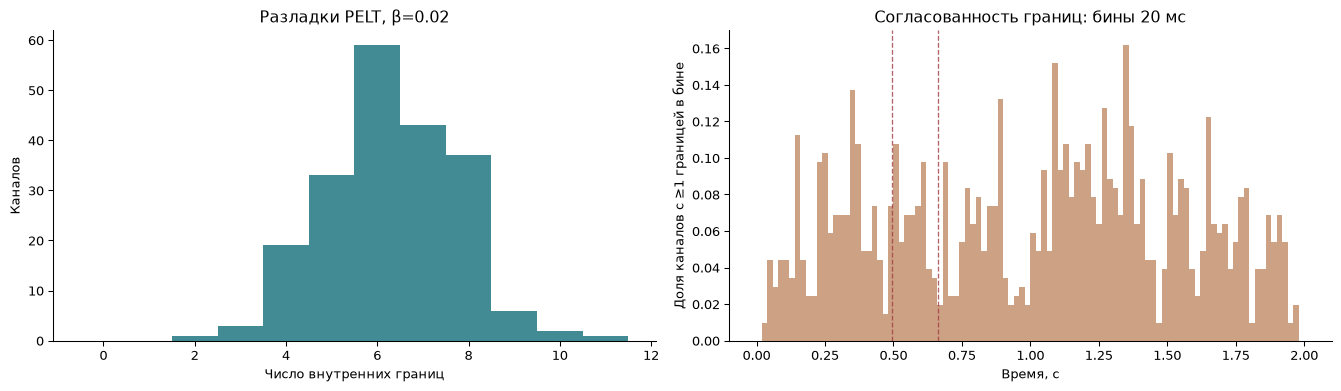

,Количество границ
count,204.000000
mean,6.313725
std,1.462034
min,2.000000
25%,5.000000
50%,6.000000
75%,7.000000
max,11.000000


In [12]:
eda.plot_segmentation_density(excel, pilot, excel_audit["markers"], bin_seconds=0.02)
plt.show()
display(pilot["table"].n_breaks.describe().to_frame("Количество границ"))


## 10. Полные таблицы и атлас Excel

В PDF для **каждого** канала есть индивидуальный график в исходных единицах, его имя и std. Получается 17 страниц по 12 рядов. Это позволяет просмотреть каналы, которые не попали в подборку примеров. CSV содержит все 204 строки и все рассчитанные признаки (12 значащих цифр), отдельные таблицы пар/корреляций/границ и словарь признаков; manifest фиксирует SHA-256 исходного Excel, версии библиотек и параметры.

In [13]:
if SAVE_ALL_CHANNELS_PDF:
    atlas = eda.export_channel_atlas(excel, EXCEL_OUTPUT / "all_channels_atlas.pdf", excel_audit["markers"])
    print("Атлас:", atlas)
excel_files = eda.export_tables(excel, EXCEL_OUTPUT, audit=excel_audit, dependence=dependence, groups=groups, pilot=pilot)
display(excel_files)
display(Markdown(
    "[Все статистики Excel](eda/excel/all_series_statistics.csv) · "
    "[PDF: все 204 канала](eda/excel/all_channels_atlas.pdf) · "
    "[Словарь признаков](eda/excel/statistics_dictionary.csv)"
))


Атлас: /Users/mac/Brain_breaks/experiments/eda/excel/all_channels_atlas.pdf


,file,size_kb
0,all_channels_atlas.pdf,3529.2
1,all_series_statistics.csv,140.3
2,channel_correlations.csv,853.9
3,channel_inventory.csv,28.2
4,manifest.json,0.8
5,pelt_all_channels.csv,18.8
6,sensor_pairs.csv,8.5
7,statistics_dictionary.csv,3.0
8,stimulus_markers.csv,0.1


[Все статистики Excel](eda/excel/all_series_statistics.csv) · [PDF: все 204 канала](eda/excel/all_channels_atlas.pdf) · [Словарь признаков](eda/excel/statistics_dictionary.csv)

## 11. MNE sample: все четыре условия и все ряды

Второй источник позволяет изучить типы датчиков по **настоящим метаданным MNE Info**, а условия — по словарю событий:

| Условие | Код | Что предъявлялось |
|---|---:|---|
| `auditory/left` | 1 | Тон в левое ухо |
| `auditory/right` | 2 | Тон в правое ухо |
| `visual/left` | 3 | Шахматный узор в левом поле зрения |
| `visual/right` | 4 | Шахматный узор в правом поле зрения |

`left/right` указывает сторону предъявления; окончания MEG-каналов 2/3 указывают ориентацию измерения. В MNE sample это один участник, а повторения условий — отдельные пробы. [Описание эксперимента и кодов](https://mne.tools/1.2/overview/datasets_index.html).

Для загрузки используется прежняя `load_sample_epochs`: добавлен обратно совместимый режим `condition=None`, чтобы загрузить четыре условия **один раз**. Данные MEG/EEG фильтруются 1–40 Гц, эпохи вырезаются от −0,1 до 0,5 с, применяется baseline `(None,0)` и стандартные для этого загрузчика MNE-проекторы. Это EDA **после данной предобработки**. Стимульные и EOG-каналы не являются теми же data picks для фильтрации. Спектры MEG/EEG выше 40 Гц здесь уже не пригодны для оценки исходной сетевой помехи.

В полную таблицу включаются даже известные плохие каналы, с явным флагом. В сравнении физиологических условий они исключаются по `Info['bads']`; произвольное удаление других каналов не применяется.

In [14]:
if RUN_MNE:
    epochs = data.load_sample_epochs(condition=None, tmin=-0.1, tmax=0.5, data_dir=str(DATA_DIR))
    mne_data, mne_times, mne_metadata, mne_inventory = eda.epochs_arrays(epochs)
    mne_analysis = eda.analyze_series(mne_data, mne_times, mne_metadata, keep_psd=False)
    mne_summary = eda.summarize_mne(epochs, mne_analysis, seed=SEED)
    condition_metrics = eda.mne_condition_metrics(epochs, mne_summary)
    print(epochs)
    print("Все ряды × время:", mne_data.shape)
    display(mne_inventory.groupby(["channel_type", "unit"]).agg(channels=("channel_name", "size"), marked_bad=("marked_bad", "sum")))
    display(mne_metadata.groupby("condition").epoch_idx.nunique().rename("Проб").to_frame())
    display(mne_analysis["statistics"].groupby("channel_type").agg(
        n_series=("series_id", "size"), constant_series=("constant", "sum"),
        nonfinite_fraction_max=("missing_fraction", "max"),
    ))
else:
    display(Markdown("Секция MNE пропущена: `RUN_MNE=False`. Все результаты Excel рассчитаны."))


<Epochs | 289 events (all good), -0.1 – 0.499 s (baseline -0.1 – 0 s), ~302.5 MiB, data loaded,
 'auditory/left': 72
 'auditory/right': 73
 'visual/left': 73
 'visual/right': 71>
Все ряды × время: (108664, 361)


,,channels,marked_bad
channel_type,unit,,
eeg,V,60,1
eog,V,1,0
grad,T/m,204,1
mag,T,102,0
stim,unknown,9,0


,Проб
condition,
auditory/left,72
auditory/right,73
visual/left,73
visual/right,71


,n_series,constant_series,nonfinite_fraction_max
channel_type,,,
eeg,17340,0,0.0
eog,289,0,0.0
grad,58956,0,0.0
mag,29478,0,0.0
stim,2601,1942,0.0


### Полнота охвата и статистики MNE

Полная таблица относится к каждой паре «проба × канал»; на карте ниже **каждая клетка** соответствует одному такому ряду. Цвет — log10(std), отдельно для каждого типа; эпохи сгруппированы по условию. Технические stim-каналы показаны отдельно: нулевая дисперсия в части эпох ожидаема и не означает поломку датчика.

Таблица по условию и каналу ниже показывает медиану и межквартильный диапазон std **между пробами**, а также другие агрегаты. Это другой уровень обобщения, чем std по отсчётам одной пробы. Детальная таблица всех рядов экспортируется в CSV.gz, чтобы не включать сотни тысяч строк HTML в ноутбук.

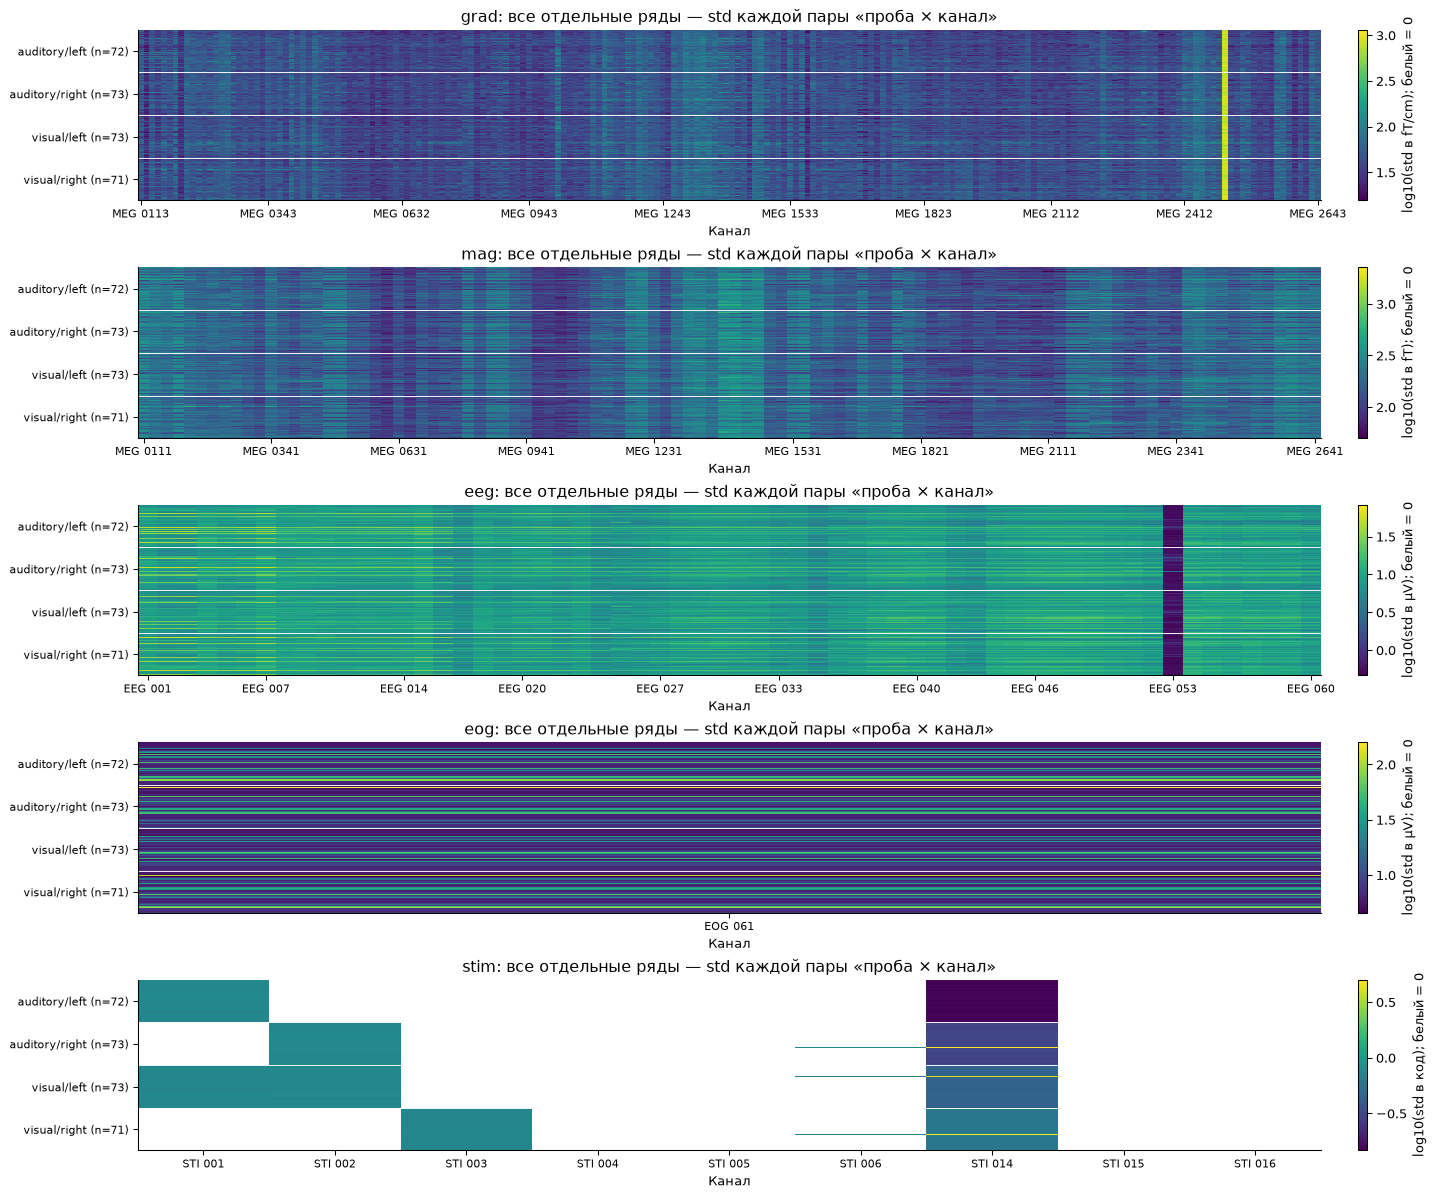

condition,channel_name,channel_type,unit,marked_bad,n_trials,median_std,q25_std,q75_std,median_ptp,median_roughness,median_acf1,median_excess_kurtosis,median_outlier_fraction
auditory/left,EEG 001,eeg,V,False,72,8.84177e-06,7.81472e-06,1.16382e-05,4.43540e-05,2.11200e-01,9.77723e-01,1.34387e-02,0.00000e+00
auditory/left,EEG 002,eeg,V,False,72,7.50115e-06,6.15831e-06,1.14847e-05,3.70513e-05,1.50367e-01,9.88678e-01,6.03115e-02,0.00000e+00
auditory/left,EEG 003,eeg,V,False,72,7.50720e-06,6.19454e-06,1.18131e-05,3.62016e-05,1.69436e-01,9.85650e-01,-5.51595e-02,0.00000e+00
auditory/left,EEG 004,eeg,V,False,72,9.59331e-06,8.22363e-06,1.16269e-05,4.88507e-05,2.39728e-01,9.71145e-01,-7.19048e-02,0.00000e+00
auditory/left,EEG 005,eeg,V,False,72,8.46447e-06,7.12166e-06,1.02769e-05,3.97944e-05,1.64114e-01,9.86542e-01,-7.89827e-02,0.00000e+00
auditory/left,EEG 006,eeg,V,False,72,8.28272e-06,7.38654e-06,1.14149e-05,4.04162e-05,1.56617e-01,9.87719e-01,-1.30077e-01,0.00000e+00
auditory/left,EEG 007,eeg,V,False,72,9.63206e-06,8.66397e-06,1.27065e-05,5.00880e-05,2.27905e-01,9.74066e-01,-3.71166e-02,0.00000e+00
auditory/left,EEG 008,eeg,V,False,72,8.83637e-06,7.99464e-06,1.07539e-05,4.54456e-05,2.09614e-01,9.78066e-01,-1.17280e-01,0.00000e+00
auditory/left,EEG 009,eeg,V,False,72,8.93997e-06,8.15787e-06,1.11219e-05,4.45978e-05,1.97039e-01,9.80600e-01,-8.47268e-02,0.00000e+00
auditory/left,EEG 010,eeg,V,False,72,8.69843e-06,7.87630e-06,1.25290e-05,4.36426e-05,1.46921e-01,9.89183e-01,-1.43555e-01,0.00000e+00


In [15]:
if RUN_MNE:
    eda.plot_mne_all_series(epochs, mne_analysis)
    plt.show()
    display(eda.scroll_table(mne_summary["channel_statistics"], max_height=450, scientific=True))


### Качественные различия условий: отклик и вариабельность

Сначала усредняем пробы **внутри каждого условия**, затем вычисляем пространственный RMS усреднённого сигнала. Это сохраняет типовую временную структуру отклика и уменьшает несогласованный между пробами шум. Пространственный RMS MEG/EEG здесь используется как описательная амплитудная мера; для EEG это не обязательно GFP при данном референсе.

Нижние панели описывают отдельные пробы: для каждого канала отношение RMS в окне **50–300 мс** к RMS до стимула, затем медиана по исправным каналам данного типа. На boxplot одна величина соответствует одной пробе. Разные типы датчиков анализируются раздельно. Нормировка на короткую baseline делает отношение чувствительным к её шуму; отношение выше 1 не является тестом статистической значимости.

Для графиков применены только стандартные коэффициенты отображения: T→fT, T/m→fT/cm, V→µV. CSV сохраняет исходные SI-единицы MNE.

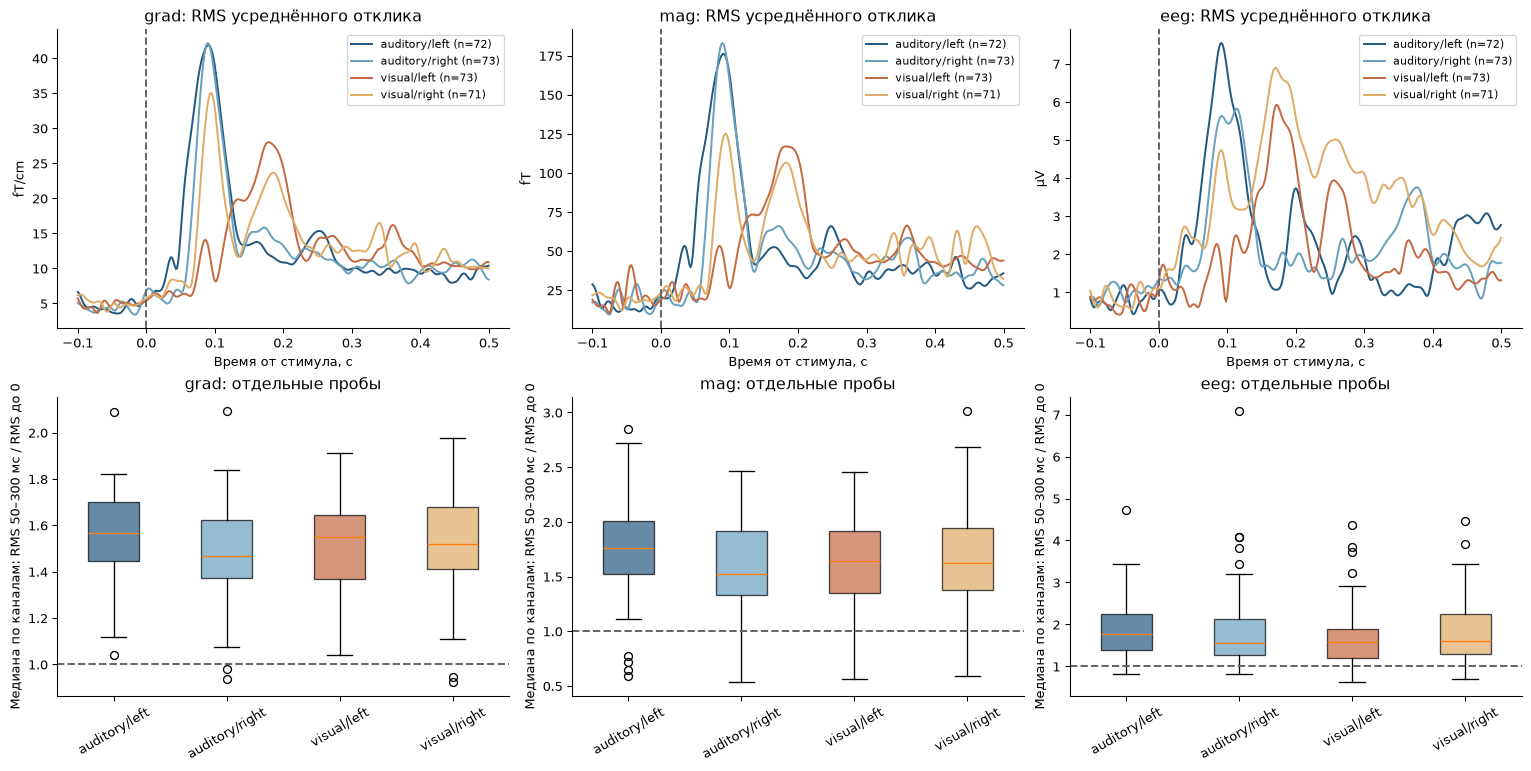

condition,channel_type,n_trials,n_good_channels,peak_time_ms,peak_rms,unit,median_response_ratio,split_half_correlation
auditory/left,grad,72,203,89.908,41.844,fT/cm,1.5681,0.72062
auditory/left,mag,72,102,91.573,176.15,fT,1.7572,0.78207
auditory/left,eeg,72,59,91.573,7.5452,µV,1.7714,0.74643
auditory/right,grad,73,203,89.908,42.175,fT/cm,1.4685,0.65458
auditory/right,mag,73,102,89.908,183.14,fT,1.5248,0.74265
auditory/right,eeg,73,59,113.22,5.8199,µV,1.5565,0.313
visual/left,grad,73,203,178.15,28.02,fT/cm,1.5484,0.62608
visual/left,mag,73,102,181.48,116.95,fT,1.6441,0.67313
visual/left,eeg,73,59,171.49,5.9181,µV,1.5928,0.77339
visual/right,grad,71,203,94.903,35.028,fT/cm,1.5214,0.69939


In [16]:
if RUN_MNE:
    eda.plot_mne_conditions(epochs, mne_summary)
    plt.show()
    display(eda.scroll_table(condition_metrics, max_height=400))


### Повторяемость отклика и нестабильность между пробами

При фиксированном `seed=42` пробы каждого условия делятся на две случайные половины. Корреляция усреднённых откликов этих половин вычисляется по каналам и времени после стимула раздельно для каждого типа датчиков. Высокая корреляция означает воспроизводимость в данном разбиении, но не независимую валидацию; это один split-half, без доверительного интервала.

Следующий график показывает медиану std каналов **для каждой пробы в порядке записи**. Он помогает заметить редкие пробы с большой амплитудой и возможную долговременную нестабильность. Высокий std требует просмотра формы и EOG/других метаданных; автоматическое отбрасывание по нему не выполняется.

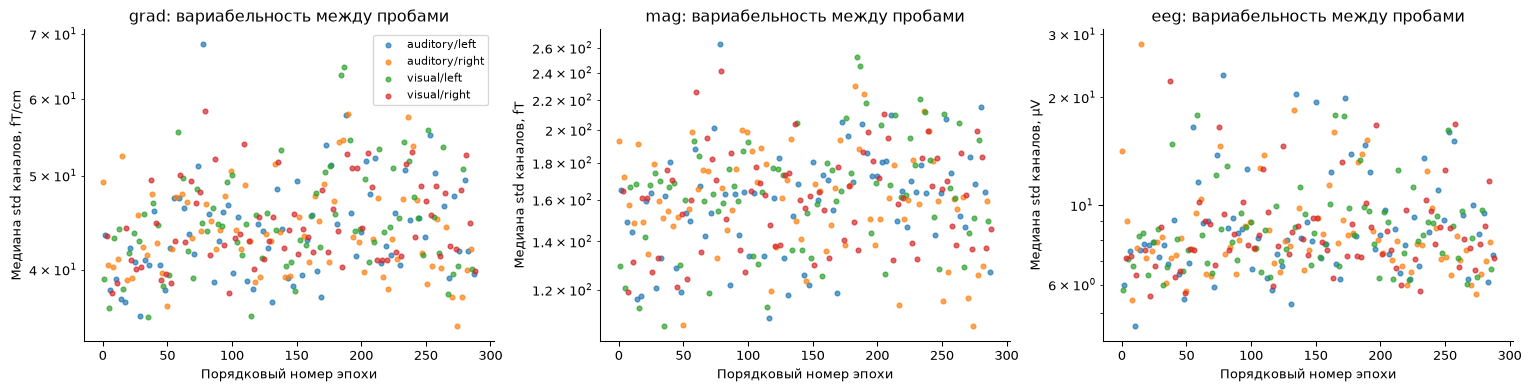

,condition,channel_type,n_trials,split_half_correlation
0,auditory/left,grad,72,0.720615
1,auditory/left,mag,72,0.782072
2,auditory/left,eeg,72,0.746430
3,auditory/right,grad,73,0.654580
4,auditory/right,mag,73,0.742651
5,auditory/right,eeg,73,0.312998
6,visual/left,grad,73,0.626078
7,visual/left,mag,73,0.673129
8,visual/left,eeg,73,0.773394
9,visual/right,grad,71,0.699390


Исследовано **289 проб × 376 каналов = 108,664 рядов** по **361 отсчёту**. Пропусков: **0**. Технические stim-каналы включены в общую таблицу статистик; их постоянство нормально для большей части эпох.

Из сравнений условий исключены каналы, заранее помеченные в Info как плохие: **MEG 2443, EEG 053**. В полном CSV они сохранены с флагом marked_bad.

**grad:** наибольшее медианное отношение RMS после/до стимула у **auditory/left** (1.57). Пики RMS усреднённого отклика в окне 50–300 мс лежат в диапазоне 90–178 мс; корреляция двух случайных половин проб — 0.63–0.72.

**mag:** наибольшее медианное отношение RMS после/до стимула у **auditory/left** (1.76). Пики RMS усреднённого отклика в окне 50–300 мс лежат в диапазоне 90–181 мс; корреляция двух случайных половин проб — 0.66–0.78.

**eeg:** наибольшее медианное отношение RMS после/до стимула у **auditory/left** (1.77). Пики RMS усреднённого отклика в окне 50–300 мс лежат в диапазоне 92–171 мс; корреляция двух случайных половин проб — 0.31–0.77.

**Как отличаются формы отклика в этой записи.** У двух слуховых условий максимум пространственного MEG-RMS возникает около 90–92 мс. У visual/left максимумы трёх типов датчиков приходятся на 171–181 мс. У visual/right максимум grad-RMS — 95 мс, mag-RMS — 95 мс, а EEG-RMS — 170 мс. Таким образом, даже внутри одной модальности форма и максимум зависят от условия и типа датчика. Все эти максимумы выбраны в окне 50–300 мс; пространственный RMS объединяет разные сенсорные компоненты.

Это наблюдения одного участника после заданной предобработки. Различия сенсорного RMS не измеряют когнитивную значимость, а split-half зависит от конкретного разбиения. Для статистического сравнения условий нужны заранее выбранные каналы/временные окна, учёт повторных измерений и независимая проверка на других участниках.

In [17]:
if RUN_MNE:
    eda.plot_mne_trial_variation(mne_summary)
    plt.show()
    display(mne_summary["reliability"])
    display(Markdown(eda.mne_findings(epochs, mne_analysis, condition_metrics)))


### Экспорт всех рядов MNE

`all_trial_channel_statistics.csv.gz` содержит полные характеристики всех проб и каналов, включая `condition`, `epoch_idx`, `channel_type`, `unit`, `marked_bad` и уникальный `series_id`. Для работы в Python: `pd.read_csv(path)` автоматически распознаёт gzip. Отдельные небольшие CSV содержат агрегаты по каналу/условию, характеристики проб и описательные показатели отклика.

In [18]:
if RUN_MNE:
    display(eda.export_mne_tables(epochs, mne_analysis, mne_summary, MNE_OUTPUT))
    display(Markdown(
        "[Все ряды MNE: CSV.gz](eda/mne/all_trial_channel_statistics.csv.gz) · "
        "[По условиям и каналам](eda/mne/condition_channel_statistics.csv) · "
        "[Показатели отклика](eda/mne/condition_metrics.csv)"
    ))


,file,size_mb
0,all_trial_channel_statistics.csv.gz,25.70
1,condition_channel_statistics.csv,0.22
2,condition_metrics.csv,0.00
3,manifest.json,0.00
4,response_ratios.csv,0.03
5,trial_statistics.csv,0.06


[Все ряды MNE: CSV.gz](eda/mne/all_trial_channel_statistics.csv.gz) · [По условиям и каналам](eda/mne/condition_channel_statistics.csv) · [Показатели отклика](eda/mne/condition_metrics.csv)

## 12. Выводы для дальнейшей работы

1. **Единицы и метаданные — часть анализа.** В Excel представлены две ориентации градиометров по именам; MNE содержит несколько физических и технических типов с разными единицами. Абсолютные амплитуды между источниками не сопоставляются без проверки единиц экспорта и предобработки.
2. **Разнообразие рядов многомерно.** Каналы различаются по масштабу, гладкости, спектру и локальному разбросу. Для демонстраций детекции полезно выбирать случаи по этим характеристикам, а не только по максимальной амплитуде или красивому графику.
3. **Общая структура важна.** Сильные корреляции и компактность PCA показывают зависимость каналов. Большое число согласованных границ не равно большому числу независимых подтверждений события.
4. **Разладки зависят от представления.** Покрытие прямоугольниками чувствительно к диапазону амплитуд; изменения тренда, дисперсии и отдельные экстремумы могут давать разные границы. Следующий эксперимент — сравнить сигналы, производные и локальные характеристики при фиксированной процедуре выбора параметров.
5. **Для оценки качества нужны аннотации.** Полезный следующий шаг — словарь STI101, подтверждение единиц/фильтров Excel и обещанная в `task.pdf` ручная разметка нескольких сотен проб. Параметры и представление следует настраивать на обучающей части, а точность проверять на отложенных пробах/участниках.

Здесь намеренно не делаются популяционные выводы и не устанавливаются физиологические причины наблюдаемых эффектов: оба источника представляют ограниченные записи одного участника каждый. Главное практическое содержание — полное описание рядов, воспроизводимые графики и конкретные гипотезы для следующего этапа.

## Воспроизводимость и источники

- В `eda/*/manifest.json` записаны параметры и версии библиотек; в Excel-manifest также SHA-256 исходного файла.
- [MNE: состав sample и экспериментальные условия](https://mne.tools/1.2/overview/datasets_index.html).
- [MNE: типы каналов, единицы, геометрия измерений](https://mne.tools/1.2/overview/implementation.html).
- [MNE: метаданные Info](https://mne.tools/1.6/auto_tutorials/intro/30_info.html).
- [SciPy: Welch PSD](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html).
- Проверки статистик, спектров, времени, маркеров и соответствия «эпоха × канал»: `python -m unittest discover -s tests -v` из корня проекта.
